<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js5/TG5_TP_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS PRAKTIKUM**


1. Pilih salah satu dataset nyata dari sklearn.datasets (misalnya iris dataset atau digits dataset).

2. Lakukan clustering dengan HDBSCAN.

3. Laporkan hasil:

* Jumlah cluster yang terbentuk.

* Banyaknya noise.

* Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu).

4.
Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

### **Langkah 1 - Load dataset**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

In [3]:
iris = load_iris()
X = iris.data
y_true = iris.target

print("Ukuran data:", X.shape)
print("Fitur:", iris.feature_names)
print("Kelas asli:", list(iris.target_names))

# Standarisasi agar tiap fitur berskala sama
X_scaled = StandardScaler().fit_transform(X)

Ukuran data: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas asli: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### **Langkah 2 - Clustering dengan HDBSCAN**

In [4]:
import hdbscan

hdb = hdbscan.HDBSCAN(min_cluster_size=5)
labels = hdb.fit_predict(X_scaled)

### **Langkah 3 - Laporan jumlah cluster dan noise**

In [5]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("Jumlah cluster :", n_clusters)
print("Jumlah noise   :", n_noise, f"({n_noise / len(labels) * 100:.1f}%)")
print("\nAnggota tiap cluster (-1 = noise):")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster : 2
Jumlah noise   : 2 (1.3%)

Anggota tiap cluster (-1 = noise):
-1     2
 0    99
 1    49
Name: count, dtype: int64


### **Langkah 4 - Visualisasi dengan PCA**

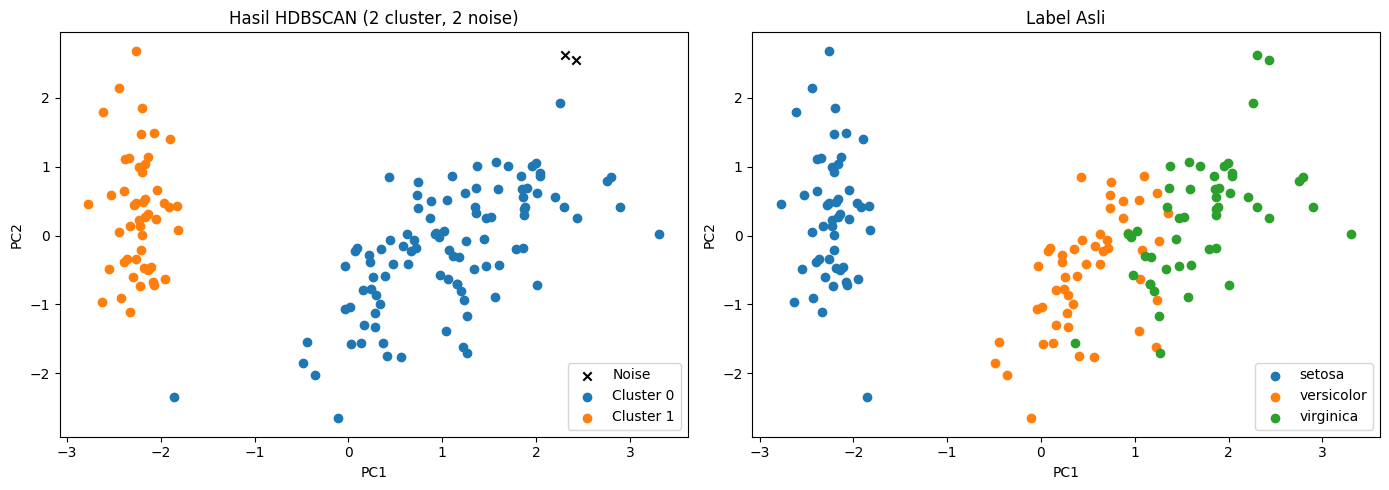

In [6]:
from sklearn.decomposition import PCA

X_pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Hasil HDBSCAN
for k in sorted(set(labels)):
    mask = labels == k
    if k == -1:
        ax[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c='black', marker='x', label='Noise')
    else:
        ax[0].scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {k}')
ax[0].set_title(f'Hasil HDBSCAN ({n_clusters} cluster, {n_noise} noise)')
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[0].legend()

# Label asli
for k, nama in enumerate(iris.target_names):
    mask = y_true == k
    ax[1].scatter(X_pca[mask, 0], X_pca[mask, 1], label=nama)
ax[1].set_title('Label Asli')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
ax[1].legend()

plt.tight_layout()
plt.show()

### **Langkah 5 - Evaluasi terhadap label asli**

In [8]:
from sklearn import metrics

print(f"Homogeneity : {metrics.homogeneity_score(y_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(y_true, labels):.3f}")
print(f"V-measure   : {metrics.v_measure_score(y_true, labels):.3f}")
print(f"ARI         : {metrics.adjusted_rand_score(y_true, labels):.3f}")
print(f"AMI         : {metrics.adjusted_mutual_info_score(y_true, labels):.3f}")

# Silhouette dihitung tanpa noise
mask = labels != -1
if len(set(labels[mask])) >= 2:
    print(f"Silhouette (tanpa noise): {metrics.silhouette_score(X_scaled[mask], labels[mask]):.3f}")

Homogeneity : 0.554
Completeness: 0.873
V-measure   : 0.678
ARI         : 0.539
AMI         : 0.672
Silhouette (tanpa noise): 0.585


In [9]:
print("\nTabel silang label asli vs cluster HDBSCAN:")
display(pd.crosstab(
    pd.Series(iris.target_names[y_true], name='Label asli'),
    pd.Series(labels, name='Cluster HDBSCAN')
))


Tabel silang label asli vs cluster HDBSCAN:


Cluster HDBSCAN,-1,0,1
Label asli,,,
setosa,0,1,49
versicolor,0,50,0
virginica,2,48,0


## **Laporan Hasil Clustering HDBSCAN pada Dataset Iris**

Dataset yang digunakan adalah Iris yang terdiri dari 150 sampel, 4 fitur, dan 3 kelas (setosa, versicolor, virginica). Data distandarisasi terlebih dahulu, kemudian diklaster menggunakan HDBSCAN dengan parameter min_cluster_size=5.


### **Hasil**
> HDBSCAN membentuk 2 cluster, yaitu Cluster 0 dengan 99 titik dan Cluster 1 dengan 49 titik. Banyaknya noise adalah 2 titik atau sekitar 1,3% dari seluruh data. Visualisasi menggunakan PCA menunjukkan satu kelompok yang terpisah jelas dari kelompok lainnya, sedangkan dua kelompok yang lain menyatu menjadi satu cluster.

### **Evaluasi**
> Hasil evaluasi terhadap label asli menunjukkan nilai Homogeneity 0,554, Completeness 0,873, V-measure 0,678, ARI 0,539, AMI 0,672, dan Silhouette Score (tanpa noise) 0,585.


### **Analisis**
>Hasil clustering HDBSCAN hanya sebagian sesuai dengan label asli dataset. Kelas setosa berhasil dipisahkan dengan baik, karena 49 dari 50 sampel setosa masuk ke Cluster 1 yang hanya berisi setosa. Hal ini wajar karena setosa memang terpisah jauh dari dua kelas lainnya pada ruang fitur.
>
> Sebaliknya, kelas versicolor dan virginica tidak berhasil dipisahkan. Keduanya tergabung dalam Cluster 0 (50 versicolor, 48 virginica, dan 1 setosa) karena sebaran datanya saling tumpang tindih sehingga wilayah padatnya bersambung dan dianggap sebagai satu cluster. Akibatnya, jumlah cluster yang terbentuk (2) berbeda dari jumlah kelas asli (3).
>
> Nilai Completeness yang tinggi (0,873) menunjukkan bahwa sebagian besar anggota tiap kelas masuk ke cluster yang sama, sedangkan nilai Homogeneity yang rendah (0,554) menunjukkan bahwa Cluster 0 berisi campuran dua kelas. Nilai ARI (0,539) dan AMI (0,672) yang tidak mendekati 1 juga menunjukkan kesesuaian yang hanya sedang. Dua titik noise yang terdeteksi keduanya berasal dari kelas virginica, yaitu titik yang letaknya menjauh dari area padat.



### **Kesimpulan**
> HDBSCAN adalah metode berbasis kepadatan yang tidak menggunakan label, sehingga ia menemukan struktur alami data (2 kelompok padat), bukan mereplikasi 3 spesies pada label asli. Hasilnya sesuai untuk memisahkan setosa, tetapi tidak sesuai untuk membedakan versicolor dan virginica.
